<a href="https://colab.research.google.com/github/sarabenzahra-afk/import_DS/blob/main/air_quality_API_lab_SB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Assignement 2.3: OpenData & Apis**




**Import libraries**

In [9]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import json
from pandas import json_normalize
import requests

# ***Part 1***

**Task 1:** Make the first request

In [17]:
# coordinates for CASABLANCA
latitude_of_the_location  = 33.5731
longitude_of_the_location = -7.5898

# API endpoints and parameters
url = "https://air-quality-api.open-meteo.com/v1/air-quality?latitude=33.5883&longitude=-7.6114&hourly=pm10,pm2_5"
parameters = {
   "latitude" : latitude_of_the_location,
   "longitude" : longitude_of_the_location,
   "hourly" : "pm2_5,pm10,us_aqi",
   "forecast_days" : 1
}

# Send the request
response = requests.get (url, params = parameters)
print("Status code", response.status_code)


# Parse the JSON response
data = response.json()

Status code 200


Status code 200 means the request was successful.

# ***Part 2***

**Task 2 :** Convert JSON to DataFrame

In [18]:
print(type(data[0]))
print(data[0])

<class 'dict'>
{'latitude': 33.6, 'longitude': -7.6000004, 'generationtime_ms': 0.5218982696533203, 'utc_offset_seconds': 0, 'timezone': 'GMT', 'timezone_abbreviation': 'GMT', 'elevation': 23.0, 'hourly_units': {'time': 'iso8601', 'pm10': 'μg/m³', 'pm2_5': 'μg/m³', 'us_aqi': 'USAQI'}, 'hourly': {'time': ['2026-06-14T00:00', '2026-06-14T01:00', '2026-06-14T02:00', '2026-06-14T03:00', '2026-06-14T04:00', '2026-06-14T05:00', '2026-06-14T06:00', '2026-06-14T07:00', '2026-06-14T08:00', '2026-06-14T09:00', '2026-06-14T10:00', '2026-06-14T11:00', '2026-06-14T12:00', '2026-06-14T13:00', '2026-06-14T14:00', '2026-06-14T15:00', '2026-06-14T16:00', '2026-06-14T17:00', '2026-06-14T18:00', '2026-06-14T19:00', '2026-06-14T20:00', '2026-06-14T21:00', '2026-06-14T22:00', '2026-06-14T23:00'], 'pm10': [20.6, 21.5, 24.2, 27.0, 31.3, 34.3, 30.5, 29.5, 26.3, 24.4, 22.7, 21.4, 21.0, 22.8, 20.0, 16.9, 17.5, 19.8, 20.5, 20.2, 19.5, 18.2, 18.0, 19.1], 'pm2_5': [10.7, 10.7, 12.2, 14.9, 17.4, 18.7, 19.0, 15.3, 1

In [27]:
df=pd.DataFrame(data[0]["hourly"])
df["time"]=pd.to_datetime(df["time"])
df.head()

,time,pm10,pm2_5,us_aqi
0,2026-06-14 00:00:00,5.0,4.6,70
1,2026-06-14 01:00:00,9.4,8.9,62
2,2026-06-14 02:00:00,12.8,12.2,51
3,2026-06-14 03:00:00,15.8,15.1,46
4,2026-06-14 04:00:00,20.1,19.5,40


# ***Part 3 :*** ***Explore Data***

**Task 3 :** Filter by pollutant level

In [20]:
# pm2.5 higher that who recommended treshold
df[df["pm2_5"]>25]

,time,pm10,pm2_5,us_aqi


**Task 4 :** Extract only day-time data

In [21]:
df["hour"]=df["time"].dt.hour
daytime_df= df[(df["hour"]>=8)&(df["hour"]<=18)]

# ***Part 4 : Visualize the Data***

**Task 5 :** Line chart of PM2.5 and PM10

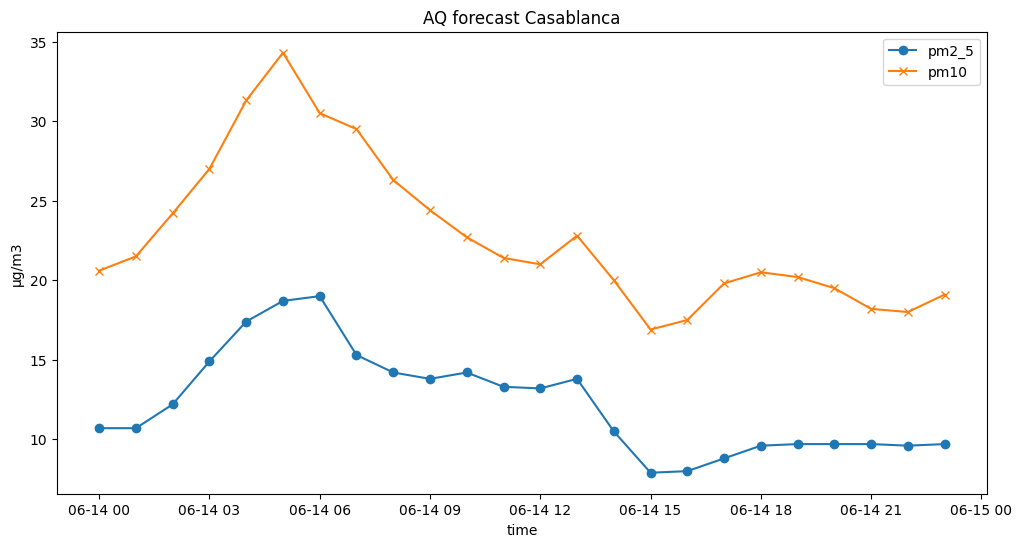

In [22]:
plt.figure(figsize=(12,6))
plt.plot(df["time"], df["pm2_5"], label="pm2_5", marker='o')
plt.plot(df["time"], df["pm10"], label= "pm10", marker='x')
plt.legend()
plt.title('AQ forecast Casablanca')
plt.xlabel('time')
plt.ylabel('µg/m3')
plt.show()


# ***Part 5: Compare 2 Cities***

**Task 6:** Same analysis for New York

In [24]:
# coordinates for NEWYORK
latitude_of_the_location  = 40.7143
longitude_of_the_location = -74.006

# API endpoints and parameters
url = "https://air-quality-api.open-meteo.com/v1/air-quality?latitude=40.7143&longitude=-74.006&hourly=pm10,pm2_5"
parameters = {
   "latitude" : latitude_of_the_location,
   "longitude" : longitude_of_the_location,
   "hourly" : "pm2_5,pm10,us_aqi",
   "forecast_days" : 1
}

# Send the request
response = requests.get (url, params = parameters)
print("Status code", response.status_code)


# Parse the JSON response
data = response.json()

Status code 200


In [34]:
print(type(data[0]))
print(data[0])

df=pd.DataFrame(data[0]["hourly"])
df["time"]=pd.to_datetime(df["time"])
df.head()


<class 'dict'>
{'latitude': 40.699997, 'longitude': -74.0, 'generationtime_ms': 0.46384334564208984, 'utc_offset_seconds': 0, 'timezone': 'GMT', 'timezone_abbreviation': 'GMT', 'elevation': 51.0, 'hourly_units': {'time': 'iso8601', 'pm10': 'μg/m³', 'pm2_5': 'μg/m³', 'us_aqi': 'USAQI'}, 'hourly': {'time': ['2026-06-14T00:00', '2026-06-14T01:00', '2026-06-14T02:00', '2026-06-14T03:00', '2026-06-14T04:00', '2026-06-14T05:00', '2026-06-14T06:00', '2026-06-14T07:00', '2026-06-14T08:00', '2026-06-14T09:00', '2026-06-14T10:00', '2026-06-14T11:00', '2026-06-14T12:00', '2026-06-14T13:00', '2026-06-14T14:00', '2026-06-14T15:00', '2026-06-14T16:00', '2026-06-14T17:00', '2026-06-14T18:00', '2026-06-14T19:00', '2026-06-14T20:00', '2026-06-14T21:00', '2026-06-14T22:00', '2026-06-14T23:00'], 'pm10': [5.0, 9.4, 12.8, 15.8, 20.1, 22.2, 19.6, 15.9, 12.5, 10.8, 10.4, 11.1, 12.3, 13.1, 10.5, 9.4, 9.2, 9.5, 10.3, 12.7, 14.6, 14.6, 13.0, 11.3], 'pm2_5': [4.6, 8.9, 12.2, 15.1, 19.5, 21.7, 19.2, 15.7, 12.3, 1

,time,pm10,pm2_5,us_aqi
0,2026-06-14 00:00:00,5.0,4.6,70
1,2026-06-14 01:00:00,9.4,8.9,62
2,2026-06-14 02:00:00,12.8,12.2,51
3,2026-06-14 03:00:00,15.8,15.1,46
4,2026-06-14 04:00:00,20.1,19.5,40


In [32]:
# pm2.5 higher that who recommended treshold
df[df["pm2_5"]>25]

,time,pm10,pm2_5,us_aqi


In [29]:
# pm2.5 higher that who recommended treshold
df[df["pm2_5"]>25]

df["hour"]=df["time"].dt.hour
daytime_df= df[(df["hour"]>=8)&(df["hour"]<=18)]

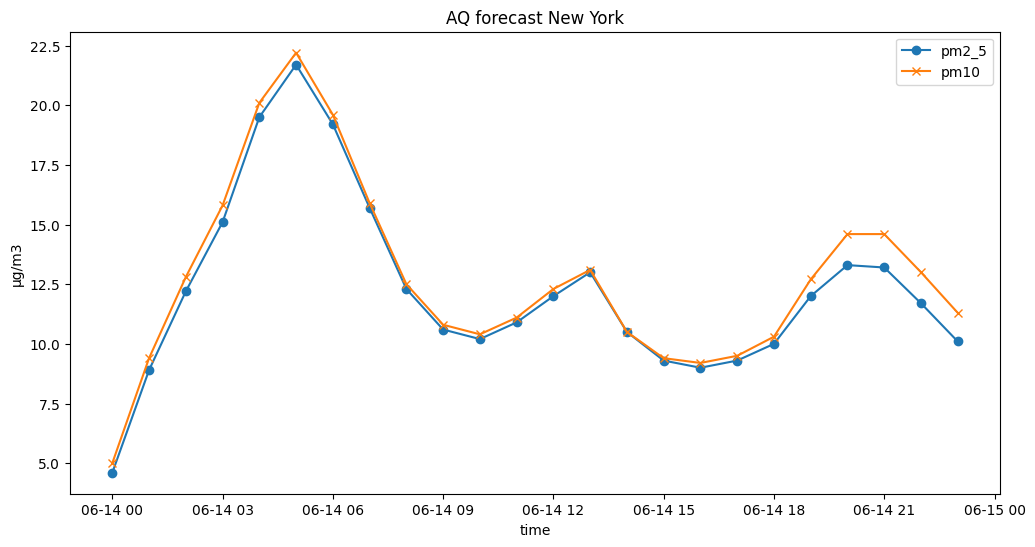

In [35]:
plt.figure(figsize=(12,6))
plt.plot(df["time"], df["pm2_5"], label="pm2_5", marker='o')
plt.plot(df["time"], df["pm10"], label= "pm10", marker='x')
plt.legend()
plt.title('AQ forecast New York')
plt.xlabel('time')
plt.ylabel('µg/m3')
plt.show()

Conclusion : CASABLANCA has the worst air quality foecast.